In [1]:
import numpy as np
from skophys.datasets import ARProcess, ARProcessMovie
import fastplotlib as fpl
from matplotlib import pyplot as plt
import seaborn as sns

%matplotlib inline

fastplotlib version from git (0.4.0) and __version__ (0.5.0) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.3) don't match.
Unable to find extension: VK_EXT_swapchain_colorspace


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅ (default),AMD RADV POLARIS10 (ACO),DiscreteGPU,Vulkan,Mesa 20.3.5 (ACO)
❗ limited,"llvmpipe (LLVM 11.0.1, 256 bits)",CPU,Vulkan,Mesa 20.3.5 (LLVM 11.0.1)
❌,"Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1)",Unknown,OpenGL,4.6 (Core Profile) Mesa 20.3.5


pygfx version from git (0.9.0) and __version__ (0.10.0) don't match.


In [89]:
X = ARProcess(
    n_timepoints=1_000,
    n_components=1,
    ar_noise_sigma=0.1,
    obs_noise_sigma=0.1,
    n_pixels_per_component=1,
    n_background_pixels=0,
    firing_probability=0.02,
)

In [90]:
X.traces.shape

(1, 1000)

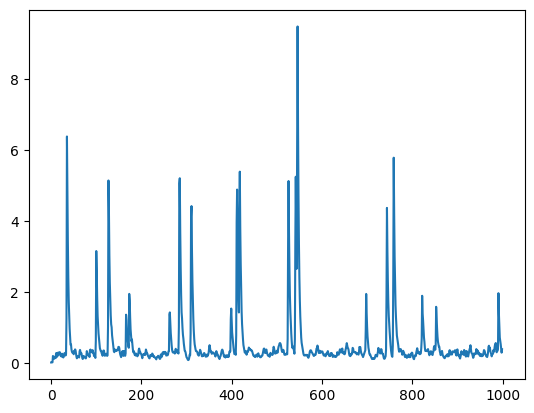

In [91]:
plt.plot(X.traces.T)

In [92]:
def make_circle(center, radius: float, p, q, n_points: int) -> np.ndarray:
    theta = np.linspace(0, 2 * np.pi, n_points)
    xs = radius * np.cos(theta * p)
    ys = radius * np.sin(theta * q)

    return np.column_stack([xs, ys]) + center

In [101]:
movie = np.zeros((1000, 24, 24))
T = movie.shape[0]
noise_sigma = 0.2

for i in range(8, T):
    for r in range(8):
        circle = np.unique(make_circle(center=(12, 12), radius=r, p=1, q=1, n_points=100).astype(int), axis=0)
        movie[i, circle[:, 0], circle[:, 1]] = X.traces[0, i - r]
        
# add observation noise
movie += np.random.normal(scale=noise_sigma, size=np.prod(movie.shape)).reshape(movie.shape)

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
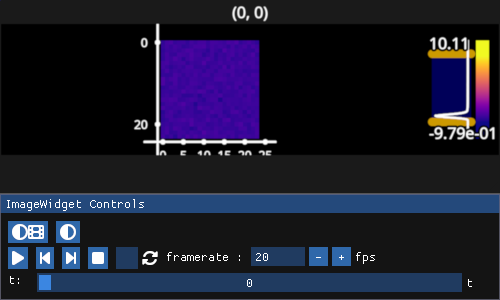

In [102]:
fpl.ImageWidget(movie).show()